In [ ]:
# 0. Programming Environment Setup

# basics
import os
import numpy as np
import pprint as pp

# pandas is used to read/process data
import pandas as pd

# machine learning dependencies
# scaling of data
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
# train/test split
from sklearn.model_selection import train_test_split
# model selection
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, validation_curve
# linear models (ordinary least squares, ridge and LASSO)
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso
# pipeline to streamline modeling pipelines
from sklearn.pipeline import Pipeline
# principal component analysis
from sklearn.decomposition import PCA
# polynomial feature mapping
from sklearn.preprocessing import PolynomialFeatures
# Dummy model as baseline
from sklearn.dummy import DummyClassifier, DummyRegressor
# Variance Threshold for feature selection
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
# metrics to measure model performance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, r2_score,
                             mean_absolute_error, mean_squared_error, max_error, mean_absolute_percentage_error)
# non-linear models
from xgboost import XGBRegressor

# save/load models
import joblib

# For the permutation importance implementation
from joblib import Parallel
from joblib import delayed
from sklearn.metrics import check_scoring
from sklearn.utils import Bunch
from sklearn.utils import check_random_state
from sklearn.utils import check_array

# plotting
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
%matplotlib inline

In [85]:
# Data Preparation 

# Fix random seed
RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)

# Import Data
df = pd.read_csv("Cleaned Data.csv")

# Remove rows containing missing values
df.dropna(inplace=True)
print(df.shape)

# Define features and target variable
TARGET = 'log_half_life'
FEATURES = [col for col in df.columns if col != TARGET and col != 'element']

# Split the data into training and testing sets
df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_SEED
)

(1666, 10)


In [ ]:
# 1. Build Baseline Models

# Build DummyRegressors
dummyregressor_mean = DummyRegressor(strategy='mean')
dummyregressor_median = DummyRegressor(strategy='median')

# Fit Dummy Regressors
dummyregressor_mean.fit(df_train[FEATURES], df_train[TARGET])
dummyregressor_median.fit(df_train[FEATURES], df_train[TARGET])

# Define a function to get regression metrics
def get_regression_metrics(model, X, y_true):
    """
    Get a dicionary with regression metrics:

    model: sklearn model with predict method
    X: feature matrix
    y_true: ground truth labels
    """
    y_predicted = model.predict(X)

    mae = mean_absolute_error(y_true, y_predicted)
    mse = mean_squared_error(y_true, y_predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_predicted)
    maximum_error = max_error(y_true, y_predicted)


    metrics_dict = {
        'mae': mae,
        'mse': mse,
        'rmse': rmse,
        'r2': r2,
        'max_error': maximum_error,
    }

    return metrics_dict

dummy_regressors = [
    ('mean', dummyregressor_mean),
    ('median', dummyregressor_median)
]

dummy_regressor_results_test = {}
dummy_regressor_results_train = {}

# Evaluate each dummy regressor on the training and test sets
for regressorname, regressor in dummy_regressors:
    dummy_regressor_results_test[regressorname] = get_regression_metrics(regressor, df_test[FEATURES], df_test[TARGET])
    dummy_regressor_results_train[regressorname] = get_regression_metrics(regressor, df_train[FEATURES], df_train[TARGET])

# Summarize results neatly in a table 
print("Dummy Regressor Results\n")

df_results_train = pd.DataFrame(dummy_regressor_results_train).T
df_results_test = pd.DataFrame(dummy_regressor_results_test).T

print("Train Set")
print(df_results_train, "\n")

print("Test Set")
print(df_results_test)

Dummy Regressor Results

Train Set
             mae        mse      rmse        r2  max_error
mean    2.450970  10.504064  3.240997  0.000000  10.536601
median  2.448978  10.514099  3.242545 -0.000955  10.636777 

Test Set
             mae        mse      rmse        r2  max_error
mean    2.420561  10.639306  3.261795 -0.006735   9.460721
median  2.419102  10.595888  3.255133 -0.002627   9.418263


In [ ]:
# 2. Build Linear Regression Model

# Use sklearn's LinearRegression model as a baseline
# Initialize the Linear Regression model
linear_regressor = LinearRegression()

# Train the model on the training data.
linear_regressor.fit(df_train[FEATURES], df_train[TARGET])

# Evaluate the model on the training and test sets.
linear_regressor_results_train = get_regression_metrics(
    linear_regressor, df_train[FEATURES], df_train[TARGET]
)
linear_regressor_results_test = get_regression_metrics(
    linear_regressor, df_test[FEATURES], df_test[TARGET]
)

print("Linear Regression Results - Train Set:", linear_regressor_results_train)
print("Linear Regression Results - Test Set:", linear_regressor_results_test)

Linear Regression Results - Train Set: {'mae': 2.249797100739325, 'mse': 9.375254418814535, 'rmse': np.float64(3.061903724615543), 'r2': 0.10746409818358471, 'max_error': 10.393666726073175}
Linear Regression Results - Test Set: {'mae': 2.307530809213211, 'mse': 10.135768659116804, 'rmse': np.float64(3.1836721971831214), 'r2': 0.04091139750325401, 'max_error': 9.82089437273368}


In [78]:
# Build Custom Linear Regression Model
class MyLinearRegression:
    def __init__(self, fit_intercept=True, standardize=False, method="normal",
                 lr=1e-2, n_iters=100, tol=1e-8, random_state=0):
        """
        method: "normal" (closed-form) or "gd" (gradient descent, MSE loss)
        """
        self.fit_intercept = fit_intercept
        self.standardize = standardize
        self.method = method
        self.lr = lr
        self.n_iters = n_iters
        self.tol = tol
        self.random_state = random_state
        self.coef_ = None
        self.intercept_ = 0.0
        self._x_mean = None
        self._x_std = None

    def _prepare_X(self, X, fit=False):
        X = np.asarray(X, dtype=float)
        if fit and self.standardize:
            self._x_mean = X.mean(axis=0, keepdims=True)
            self._x_std = X.std(axis=0, keepdims=True)
            self._x_std[self._x_std == 0] = 1.0
        if self.standardize:
            Xs = (X - self._x_mean) / self._x_std
        else:
            Xs = X
        if self.fit_intercept:
            Xs = np.c_[np.ones((Xs.shape[0], 1)), Xs]
        return Xs

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1,)

        Xp = self._prepare_X(X, fit=True)

        # NORMAL EQUATION
        if self.method == "normal":
            # theta = (X^T X)^{-1} X^T y  with ridge-like jitter for stability
            XT_X = Xp.T @ Xp
            # add tiny jitter to diagonal to avoid singular matrix in edge cases
            jitter = 1e-12 * np.eye(XT_X.shape[0])
            theta = np.linalg.pinv(XT_X + jitter) @ (Xp.T @ y)

        # GRADIENT DESCENT
        elif self.method == "gd":
            # Add your code here
            n_features = Xp.shape[1]
            theta = rng.normal(scale=0.01, size=n_features)
            prev_loss = np.inf
            for i in range(self.n_iters):
                y_pred = Xp @ theta
                residuals = y_pred - y
                loss = 0.5 * np.mean(residuals ** 2)
                if abs(prev_loss - loss) < self.tol:
                    break
                prev_loss = loss
                grad = (Xp.T @ residuals) / len(y)
                theta -= self.lr * grad
        else:
            raise ValueError("method must be 'normal' or 'gd'")

        # unpack theta into intercept and coefficients
        if self.fit_intercept:
            self.intercept_ = float(theta[0])
            self.coef_ = theta[1:]
        else:
            self.intercept_ = 0.0
            self.coef_ = theta
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if self.standardize:
            Xs = (X - self._x_mean) / self._x_std
        else:
            Xs = X
        return self.intercept_ + Xs @ self.coef_

# Initialize two Linear Regression model with different optimization methods
my_linear_regressor_gd = MyLinearRegression(fit_intercept=True, standardize=True, method="gd")
my_linear_regressor_cf = MyLinearRegression(fit_intercept=True, standardize=True, method="normal")

# Train the model on the training data
my_linear_regressor_gd.fit(df_train[FEATURES], df_train[TARGET])
my_linear_regressor_cf.fit(df_train[FEATURES], df_train[TARGET])

# Evaluate the model on the training and test sets
my_linear_regressor_gd_results_test = get_regression_metrics(
    my_linear_regressor_gd, df_test[FEATURES], df_test[TARGET]
)
my_linear_regressor_cf_results_test = get_regression_metrics(
    my_linear_regressor_cf, df_test[FEATURES], df_test[TARGET]
)

# Evaluate gd model with different learning rates and iterations
my_linear_regressor_gd_custom = MyLinearRegression(fit_intercept=True, standardize=True, method="gd",lr=1e-2, n_iters=1000)
my_linear_regressor_gd_custom.fit(df_train[FEATURES], df_train[TARGET])
my_linear_regressor_gd_custom_results_test = get_regression_metrics(
    my_linear_regressor_gd_custom, df_test[FEATURES], df_test[TARGET]
)

# Summarize results neatly in a table and compare
# Create DataFrames for testing results
df_results_sklearn_test = pd.DataFrame(
    [linear_regressor_results_test],
    index=['Sklearn Linear Regression']
)
df_results_gd_test = pd.DataFrame(
    [my_linear_regressor_gd_results_test],
    index=['Gradient Descent']
)
df_results_cf_test = pd.DataFrame(
    [my_linear_regressor_cf_results_test],
    index=['Closed Form']
)

df_results_gd_custom_test = pd.DataFrame(
    [my_linear_regressor_gd_custom_results_test],   
    index=['Custom GD']
)

# Concatenate the DataFrames for comparison
df_comparison = pd.concat({
    'Sklearn Linear Regression - Test': df_results_sklearn_test,
    'Closed Form - Test': df_results_cf_test,
    'Gradient Descent - Test': df_results_gd_test,
    'Custom GD - Test': df_results_gd_custom_test
}, names=['Model', 'Dataset'])

display(df_comparison)

,,mae,mse,rmse,r2,max_error
Model,Dataset,,,,,
Sklearn Linear Regression - Test,Sklearn Linear Regression,2.307531,10.135769,3.183672,0.040911,9.820894
Closed Form - Test,Closed Form,2.307531,10.135769,3.183672,0.040911,9.820894
Gradient Descent - Test,Gradient Descent,2.395781,10.721565,3.274380,-0.014519,9.819976
Custom GD - Test,Custom GD,2.343529,10.450502,3.232724,0.011130,9.783346


In [89]:
# Different combinations of learning rates and iterations
learning_rates = [1e-4, 1e-3, 1e-2, 1e-1]
iterations = [1000, 5000, 10000]

experiment_results = []

for lr in learning_rates:
    for n in iterations:

        # Create a new model
        model = MyLinearRegression(
            standardize=True,
            method="gd",
            lr=lr,
            n_iters=n
        )

        # Train the model
        model.fit(df_train[FEATURES], df_train[TARGET])

        # Evaluate on test data
        metrics = get_regression_metrics(
            model,
            df_test[FEATURES],
            df_test[TARGET]
        )

        # Store results
        experiment_results.append({
            'Learning Rate': lr,
            'Iterations': n,
            'MAE': metrics['mae'],
            'MSE': metrics['mse'],
            'RSME': metrics['rmse'],
            'R2': metrics['r2'],
            'Max Error': metrics['max_error'],
        })

df_experiment = pd.DataFrame(experiment_results)

df_experiment = df_experiment.sort_values(
    by='MAE',
    ascending=True
)

display(df_experiment)

,Learning Rate,Iterations,MAE,MSE,RSME,R2,Max Error
10,0.1000,5000,2.307864,10.135824,3.183681,0.040906,9.811436
11,0.1000,10000,2.307864,10.135824,3.183681,0.040906,9.811436
9,0.1000,1000,2.311402,10.147161,3.185461,0.039833,9.798255
8,0.0100,10000,2.311407,10.147215,3.185469,0.039828,9.798204
7,0.0100,5000,2.316686,10.199131,3.193608,0.034916,9.749702
5,0.0010,10000,2.343525,10.450485,3.232721,0.011132,9.783379
6,0.0100,1000,2.343529,10.450502,3.232724,0.011130,9.783346
4,0.0010,5000,2.351302,10.533357,3.245513,0.003290,9.949837
3,0.0010,1000,2.396297,10.723302,3.274645,-0.014683,9.823303
2,0.0001,10000,2.396348,10.723475,3.274672,-0.014700,9.823635


In [ ]:
# DECIDE IF KEEPING

from ipywidgets import interact, FloatLogSlider, IntSlider, fixed
from IPython.display import display

def run_gd_and_plot(lr, n_iters, df, FEATURES, TARGET, get_regression_metrics):
    model = MyLinearRegression(
        fit_intercept=True,
        standardize=True,
        method="gd",
        lr=lr,
        n_iters=n_iters,
        tol=1e-12,
        random_state=0
    )
    model.fit(df[FEATURES].values, df[TARGET].values)

    metrics = get_regression_metrics(model, df[FEATURES], df[TARGET])

    plt.figure(figsize=(6,4))
    plt.xlabel("Iteration")
    plt.ylabel("Loss (MSE/2)")
    plt.title(f"lr={lr:.1e}, iters={n_iters}, MAE={metrics['mae']:.2f}, R2={metrics['r2']:.2f}")
    plt.plot(df[TARGET].values, model.predict(df[FEATURES].values), 'o', alpha=0.3)
    plt.plot(df[TARGET].values, df[TARGET].values, 'k--', label="y=x")
    plt.xlim(0.95*df[TARGET].min(), 1.05*df[TARGET].max())
    plt.ylim(0.95*df[TARGET].min(), 1.05*df[TARGET].max())
    plt.legend()
    plt.show()

interact(
    run_gd_and_plot,
    lr=FloatLogSlider(value=1e-4, base=10, min=-5, max=0, step=0.1, description="learning rate"),
    n_iters=IntSlider(value=100, min=10, max=10000, step=50, description="iterations"),
    df=fixed(df_train),
    FEATURES=fixed(FEATURES),
    TARGET=fixed(TARGET),
    get_regression_metrics=fixed(get_regression_metrics)
)

interactive(children=(FloatLogSlider(value=0.0001, description='learning rate', max=0.0, min=-5.0), IntSlider(…

<function __main__.run_gd_and_plot(lr, n_iters, df, FEATURES, TARGET, get_regression_metrics)>

In [81]:
# 3. Building the Ridge Regression Model

# Train a ridge regression model with the default regularization
ridge = Ridge(alpha=1.0)
ridge.fit(df_train[FEATURES], df_train[TARGET])

''' 
Get the metrics on the train and the test set using the get_regression_metrics function.
Compare with the dummy mean model and the linear regression, all evaluated on the same split.
'''

models_to_compare = {
    'dummy (mean)': dummyregressor_mean,
    'linear regression': linear_regressor,
    'ridge (alpha=1)': ridge,
}

train_results = {}
test_results = {}

for name, m in models_to_compare.items():
    train_results[name] = get_regression_metrics(m, df_train[FEATURES], df_train[TARGET])
    test_results[name]  = get_regression_metrics(m, df_test[FEATURES], df_test[TARGET])

df_train_results = pd.DataFrame(train_results).T
df_test_results = pd.DataFrame(test_results).T

comparison = pd.concat({
    'train': df_train_results,
    'test': df_test_results
}, axis=1)

comparison

train                                            \
                        mae        mse      rmse        r2  max_error   
dummy (mean)       2.450970  10.504064  3.240997  0.000000  10.536601   
linear regression  2.249797   9.375254  3.061904  0.107464  10.393667   
ridge (alpha=1)    2.251798   9.403425  3.066500  0.104782  10.267050   

                       test                                           
                        mae        mse      rmse        r2 max_error  
dummy (mean)       2.420561  10.639306  3.261795 -0.006735  9.460721  
linear regression  2.307531  10.135769  3.183672  0.040911  9.820894  
ridge (alpha=1)    2.312643  10.203073  3.194225  0.034543  9.764367

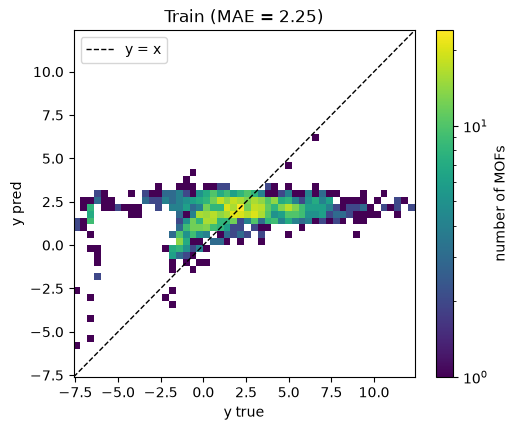

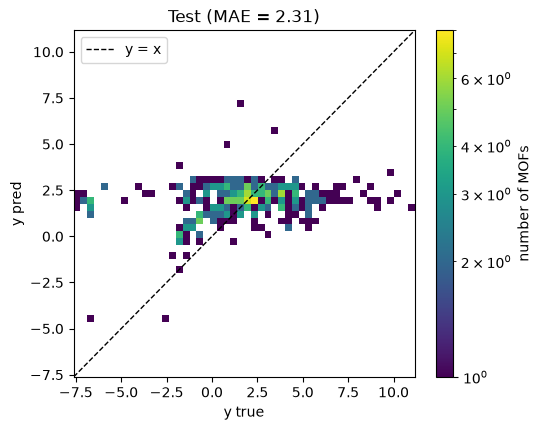

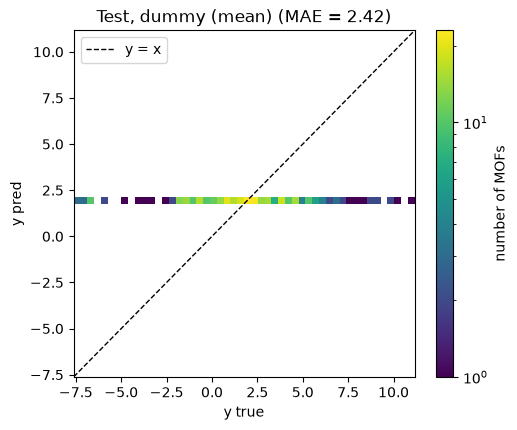

In [82]:
# Evaluate Ridge Regression model performance

def hist_density(y_true, y_pred, xlabel='y true', ylabel='y pred', title=None, bins=50):
    """Parity plot drawn as a 2D histogram.

    y_true: true values
    y_pred: predicted values
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    mae = np.mean(np.abs(y_true - y_pred))

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    h = ax.hist2d(y_true, y_pred, bins=bins, range=[lims, lims], cmin=1, cmap='viridis', norm=LogNorm())
    fig.colorbar(h[3], ax=ax, label='number of MOFs')
    ax.plot(lims, lims, 'k--', lw=1, label='y = x')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"{title} (MAE = {mae:.2f})" if title else f"MAE = {mae:.2f}")
    ax.legend(loc='upper left')
    plt.show()

# Create dictionaries with training and test results to create parity plots
res_train = {
    'y true': df_train[TARGET].values,
    'y pred': ridge.predict(df_train[FEATURES])
}

res_test = {
    'y true': df_test[TARGET].values,
    'y pred': ridge.predict(df_test[FEATURES])
}

hist_density(res_train['y true'], res_train['y pred'], xlabel='y true', ylabel='y pred', title='Train')
hist_density(res_test['y true'], res_test['y pred'], xlabel='y true', ylabel='y pred', title='Test')

# parity plot of a dummy mean model
hist_density(df_test[TARGET], dummyregressor_mean.predict(df_test[FEATURES]),
             xlabel='y true', ylabel='y pred', title='Test, dummy (mean)')

Ridge (scaled) - Train: {'mae': 2.2499204246263282, 'mse': 9.375493308099443, 'rmse': np.float64(3.061942734294592), 'r2': 0.1074413556260162, 'max_error': 10.348920736655819}
Ridge (scaled) - Test:  {'mae': 2.308255399861986, 'mse': 10.139489537538413, 'rmse': np.float64(3.184256512521944), 'r2': 0.0405593125055137, 'max_error': 9.805420379686831}
Ridge (unscaled)    - Test:  {'mae': 2.3126434456705853, 'mse': 10.203072522582852, 'rmse': np.float64(3.194224870384496), 'r2': 0.03454282591039093, 'max_error': 9.764366794145047}


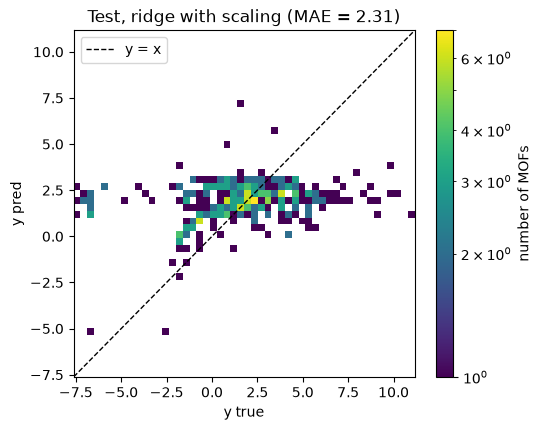

In [83]:
# Build Ridge Regression Pipeline 
pipe_ridge_regression = Pipeline(
   [
       ('scaling', StandardScaler()),
       ('ridge', Ridge(alpha=1))
   ]
)

# fit the pipeline, calculate the metrics and make the parity plots
pipe_ridge_regression.fit(df_train[FEATURES], df_train[TARGET])

print("Ridge (scaled) - Train:", get_regression_metrics(pipe_ridge_regression, df_train[FEATURES], df_train[TARGET]))
print("Ridge (scaled) - Test: ", get_regression_metrics(pipe_ridge_regression, df_test[FEATURES], df_test[TARGET]))
print("Ridge (unscaled)    - Test: ", get_regression_metrics(ridge, df_test[FEATURES], df_test[TARGET]))

hist_density(df_test[TARGET], pipe_ridge_regression.predict(df_test[FEATURES]), title='Test, ridge with scaling')

In [56]:
# the single descriptor that is most correlated with the target
ONE_FEATURE = (
    df_train[FEATURES]
    .corrwith(df_train[TARGET], method='spearman')
    .abs()
    .idxmax()
)
print(f"Descriptor: {ONE_FEATURE}")

# a small training set (30 isotopes)
df_small = df_train.sample(n=30, random_state=RANDOM_SEED)
# and a validation set taken from the remaining training data 
df_val_1d = df_train.drop(df_small.index).sample(n=500, random_state=RANDOM_SEED)

# small datasets with just 1 feature
X_small, y_small = df_small[[ONE_FEATURE]], df_small[TARGET]
X_val_1d, y_val_1d = df_val_1d[[ONE_FEATURE]], df_val_1d[TARGET]

Descriptor: N/Z


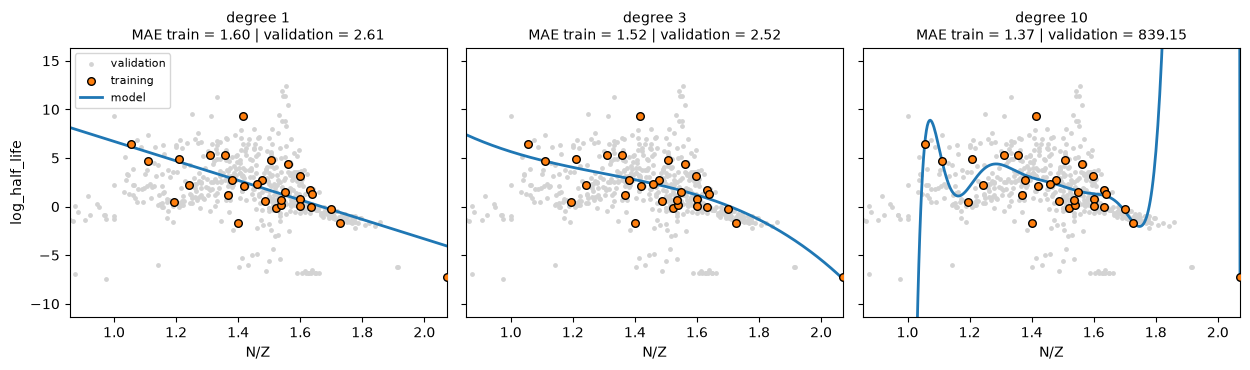

In [57]:
def make_poly_model(degree, alpha=1e-8):
    """Pipeline: scaling -> polynomial feature mapping -> scaling -> ridge regression."""
    return Pipeline([
        ('scaling', StandardScaler()), # 1st scaling: so features scales match
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('poly_scaling', StandardScaler()), # 2nd scaling: so polynomial terms are on the same scale
        ('ridge', Ridge(alpha=alpha)),
    ])


def plot_1d_fits(models):
    """Plots each fitted curve with the training and validation data.
    
    Args:
       models: dictionary {label: fitted model}
    """
    x_min = min(X_small[ONE_FEATURE].min(), X_val_1d[ONE_FEATURE].quantile(0.01))
    x_max = max(X_small[ONE_FEATURE].max(), X_val_1d[ONE_FEATURE].quantile(0.99))
    x_grid = pd.DataFrame({ONE_FEATURE: np.linspace(x_min, x_max, 400)})
    y_margin = 0.2 * (y_val_1d.max() - y_val_1d.min())
    y_lim = (y_val_1d.min() - y_margin, y_val_1d.max() + y_margin)

    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.8), sharey=True, squeeze=False)
    for ax, (label, model) in zip(axes[0], models.items()):
        mae_train = mean_absolute_error(y_small, model.predict(X_small))
        mae_val = mean_absolute_error(y_val_1d, model.predict(X_val_1d))
        ax.scatter(X_val_1d, y_val_1d, s=6, color='lightgray', label='validation')
        ax.scatter(X_small, y_small, s=30, color='tab:orange', edgecolor='k', zorder=3, label='training')
        ax.plot(x_grid[ONE_FEATURE], model.predict(x_grid), color='tab:blue', lw=2, label='model')
        ax.set_ylim(*y_lim)
        ax.set_xlim(x_min, x_max)
        ax.set_title(f"{label}\nMAE train = {mae_train:.2f} | validation = {mae_val:.2f}", fontsize=10)
        ax.set_xlabel(ONE_FEATURE)
    axes[0][0].set_ylabel(TARGET)
    axes[0][0].legend(fontsize=8, loc='upper left')
    plt.tight_layout()
    plt.show()

degrees = [1, 3, 10]
poly_models = {}
for degree in degrees:
    model = make_poly_model(degree)
    model.fit(X_small, y_small)
    poly_models[f"degree {degree}"] = model

plot_1d_fits(poly_models)

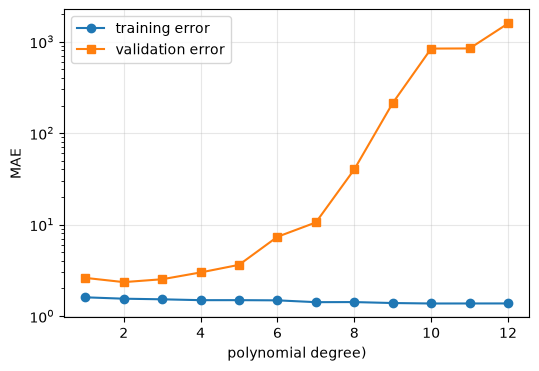

In [58]:
# training and validation error as a function of the polynomial degree
all_degrees = range(1, 13)
mae_train, mae_val = [], []
for degree in all_degrees:
    model = make_poly_model(degree).fit(X_small, y_small)
    mae_train.append(mean_absolute_error(y_small, model.predict(X_small)))
    mae_val.append(mean_absolute_error(y_val_1d, model.predict(X_val_1d)))

plt.figure(figsize=(6, 4))
plt.plot(all_degrees, mae_train, 'o-', label='training error')
plt.plot(all_degrees, mae_val, 's-', label='validation error')
plt.yscale('log')
plt.xlabel('polynomial degree)')
plt.ylabel('MAE')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [59]:
# number of features after a degree-2 polynomial mapping of all descriptors
d = len(FEATURES)
n_poly = PolynomialFeatures(degree=2, include_bias=False).fit(df_train[FEATURES]).n_output_features_
print(f"{d} descriptors")
print(f"{n_poly} polynomical features")
print(f"Number of training points: {len(df_train)}")

8 descriptors
44 polynomical features
Number of training points: 1332


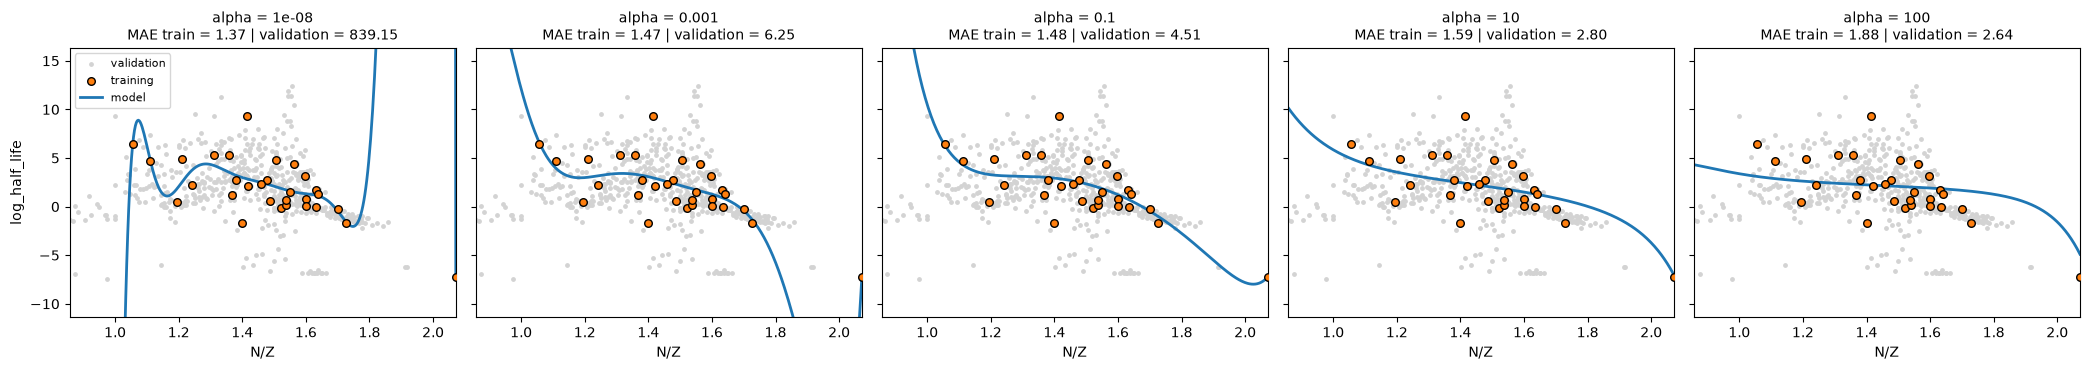

In [60]:
# 8. Regularization 

# Regularization Strength
DEGREE = 10
alphas = [1e-8, 1e-3, 1e-1, 10, 100]
ridge_models = {}
for alpha in alphas:
    model = make_poly_model(DEGREE, alpha=alpha)
    model.fit(X_small, y_small)
    ridge_models[f"alpha = {alpha:g}"] = model

plot_1d_fits(ridge_models)

In [61]:
# we can take a look at what happens to the weights as alpha increases
for label, model in ridge_models.items():
    print(f"{label}: ||weights|| = {np.linalg.norm(model['ridge'].coef_)}")

alpha = 1e-08: ||weights|| = 4145.704908627932
alpha = 0.001: ||weights|| = 27.705714977825103
alpha = 0.1: ||weights|| = 3.5993389000400553
alpha = 10: ||weights|| = 1.095010929145353
alpha = 100: ||weights|| = 0.5108652063411407


In [62]:
pipe_lasso = Pipeline(
   [
       ('scaling', StandardScaler()),
       ('lasso', Lasso(alpha=0.01, max_iter=10000))
   ]
)
pipe_lasso.fit(df_train[FEATURES], df_train[TARGET])
print("LASSO          - Train:", get_regression_metrics(pipe_lasso, df_train[FEATURES], df_train[TARGET]))
print("LASSO          - Test: ", get_regression_metrics(pipe_lasso, df_test[FEATURES], df_test[TARGET]))
print("Ridge (scaled) - Test: ", get_regression_metrics(pipe_w_scaling, df_test[FEATURES], df_test[TARGET]))

LASSO          - Train: {'mae': 2.2484776395933226, 'mse': 9.386728776353245, 'rmse': np.float64(3.063776880967876), 'r2': 0.10637172504936643, 'max_error': 10.277912087413766}
LASSO          - Test:  {'mae': 2.308937858139902, 'mse': 10.175432618598682, 'rmse': np.float64(3.1898953930495404), 'r2': 0.03715822862693552, 'max_error': 9.867708655386991}
Ridge (scaled) - Test:  {'mae': 2.308255399861986, 'mse': 10.139489537538413, 'rmse': np.float64(3.184256512521944), 'r2': 0.0405593125055137, 'max_error': 9.805420379686831}


In [63]:
# count the weights that are exactly zero
print(f"LASSO: {(pipe_lasso['lasso'].coef_ == 0).sum()} of {len((pipe_lasso['lasso'].coef_))} weights are exactly zero")
print(f"Ridge: {(pipe_w_scaling['ridge'].coef_ == 0).sum()} of {len((pipe_w_scaling['ridge'].coef_))} weights are exactly zero")

LASSO: 3 of 8 weights are exactly zero
Ridge: 0 of 8 weights are exactly zero


Fitting 5 folds for each of 26 candidates, totalling 130 fits
Grid search   best parameters: {'ridge__alpha': np.float64(0.03162277660168379), 'scaling': MinMaxScaler()} , CV MAE = 2.257348325686084
Train: {'mae': 2.249583182484754, 'mse': 9.375926877683481, 'rmse': np.float64(3.0620135332299694), 'r2': 0.1074000792614076, 'max_error': 10.293802201789955}
Test:  {'mae': 2.3077398158558897, 'mse': 10.140089934772101, 'rmse': np.float64(3.184350787016421), 'r2': 0.04050250042118475, 'max_error': 9.816597025160945}


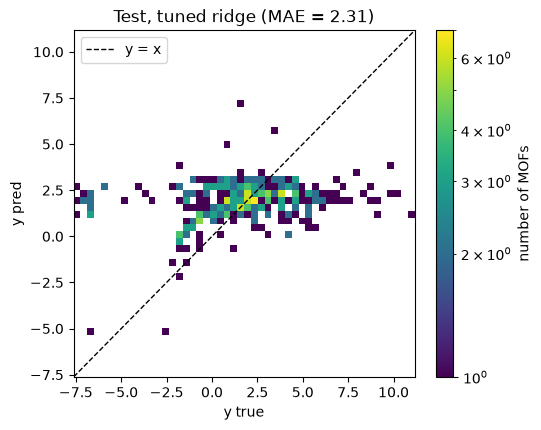

In [64]:
# 9. Hyperparameter Optimization

# Define the parameter grid and the grid search object
param_grid = {
                    'scaling': [MinMaxScaler(), StandardScaler()], # test different scaling methods
                    'ridge__alpha': np.logspace(-3, 3, 13)
            }

grid_ridge = GridSearchCV(pipe_w_scaling, param_grid=param_grid,
                          cv=5, scoring='neg_mean_absolute_error', verbose=1, n_jobs=2)

# run the grid search by calling the fit method
grid_ridge.fit(df_train[FEATURES], df_train[TARGET])

print("Grid search   best parameters:", grid_ridge.best_params_, f", CV MAE = {-grid_ridge.best_score_}")

# get the performance metrics
print("Train:", get_regression_metrics(grid_ridge.best_estimator_, df_train[FEATURES], df_train[TARGET]))
print("Test: ", get_regression_metrics(grid_ridge.best_estimator_, df_test[FEATURES], df_test[TARGET]))
hist_density(df_test[TARGET], grid_ridge.predict(df_test[FEATURES]), title='Test, tuned ridge')

Fitting 5 folds for each of 36 candidates, totalling 180 fits
XGBoost Best Parameters:
{'xgb__learning_rate': 0.05, 'xgb__max_depth': 5, 'xgb__n_estimators': 500, 'xgb__subsample': 0.8}
Cross-Validation MAE: 0.839549383386843
XGBoost - Train:
{'mae': 0.21277104724048407, 'mse': 0.08486636168137077, 'rmse': np.float64(0.29131831676255915), 'r2': 0.9919206166282645, 'max_error': 1.5752564460860015}
XGBoost - Test:
{'mae': 0.8576818348756448, 'mse': 1.828733099123376, 'rmse': np.float64(1.352306584737121), 'r2': 0.8269576653369857, 'max_error': 7.395647922240329}


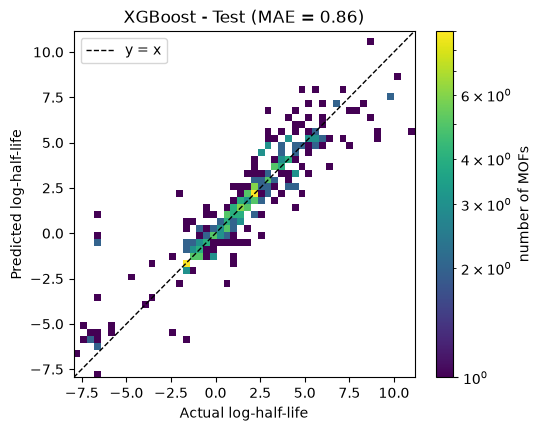

In [69]:
# 10. XGBoost

# Build XGBoost pipeline
pipe_xgb = Pipeline([
    ('xgb', XGBRegressor(
        objective='reg:squarederror',
        random_state=RANDOM_SEED,
        tree_method='hist',
        n_jobs=1
    ))
])

# Define hyperparameter grid
param_grid_xgb = {
    'xgb__n_estimators': [100, 300, 500],
    'xgb__max_depth': [3, 5],
    'xgb__learning_rate': [0.01, 0.05, 0.1],
    'xgb__subsample': [0.8, 1.0]
}

# 5-fold cross-validation
grid_xgb = GridSearchCV(
    pipe_xgb,
    param_grid=param_grid_xgb,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=2,
    verbose=1
)

# Train using the existing training dataset
grid_xgb.fit(
    df_train[FEATURES],
    df_train[TARGET]
)

# Best parameters
print("XGBoost Best Parameters:")
print(grid_xgb.best_params_)

print("Cross-Validation MAE:",
      -grid_xgb.best_score_)

# Evaluate training performance
print("XGBoost - Train:")
print(get_regression_metrics(
    grid_xgb.best_estimator_,
    df_train[FEATURES],
    df_train[TARGET]
))

# Evaluate test performance
print("XGBoost - Test:")
print(get_regression_metrics(
    grid_xgb.best_estimator_,
    df_test[FEATURES],
    df_test[TARGET]
))

hist_density(
    df_test[TARGET],
    grid_xgb.predict(df_test[FEATURES]),
    xlabel='Actual log-half-life',
    ylabel='Predicted log-half-life',
    title='XGBoost - Test'
)

In [66]:
# 11. Model Comparison

models_to_compare = {
    'Dummy Mean': (dummyregressor_mean, FEATURES),
    'Linear Regression': (linear_regressor, FEATURES),
    'Ridge (Optimized)': (
        grid_ridge.best_estimator_, FEATURES
    ),
    'XGBoost (Optimized)': (
        grid_xgb.best_estimator_, FEATURES
    )
}

train_results = {}
test_results = {}

for name, (model, features) in models_to_compare.items():

    train_results[name] = get_regression_metrics(
        model,
        df_train[features],
        df_train[TARGET]
    )

    test_results[name] = get_regression_metrics(
        model,
        df_test[features],
        df_test[TARGET]
    )

df_train_results = pd.DataFrame(train_results).T
df_test_results = pd.DataFrame(test_results).T

print("Training Results:")
display(df_train_results)

print("Testing Results:")
display(df_test_results)

Training Results:


,mae,mse,rmse,r2,max_error
Dummy Mean,2.450970,10.504064,3.240997,0.000000,10.536601
Linear Regression,2.249797,9.375254,3.061904,0.107464,10.393667
Ridge (Optimized),2.249583,9.375927,3.062014,0.107400,10.293802
XGBoost (Optimized),0.212771,0.084866,0.291318,0.991921,1.575256


Testing Results:


,mae,mse,rmse,r2,max_error
Dummy Mean,2.420561,10.639306,3.261795,-0.006735,9.460721
Linear Regression,2.307531,10.135769,3.183672,0.040911,9.820894
Ridge (Optimized),2.307740,10.140090,3.184351,0.040503,9.816597
XGBoost (Optimized),0.857682,1.828733,1.352307,0.826958,7.395648


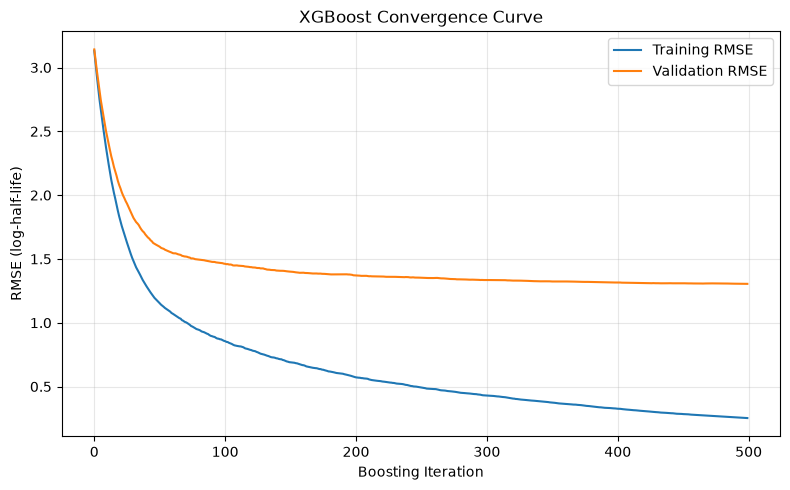

In [68]:
# 12. XGBoost Convergence Curve

# Create validation set from training data
X_fit, X_val, y_fit, y_val = train_test_split(
    df_train[FEATURES],
    df_train[TARGET],
    test_size=0.2,
    random_state=RANDOM_SEED
)

# Use optimized hyperparameters
best_params = {
    key.replace('xgb__', ''): value
    for key, value in grid_xgb.best_params_.items()
}

# Initialize diagnostic XGBoost model
xgb_diagnostic = XGBRegressor(
    objective='reg:squarederror',
    random_state=RANDOM_SEED,
    tree_method='hist',
    eval_metric='rmse',
    n_jobs=2,
    **best_params
)

# Train while tracking error
xgb_diagnostic.fit(
    X_fit,
    y_fit,
    eval_set=[
        (X_fit, y_fit),
        (X_val, y_val)
    ],
    verbose=False
)

# Extract training history
results = xgb_diagnostic.evals_result()

train_rmse = results['validation_0']['rmse']
val_rmse = results['validation_1']['rmse']

# Plot convergence curve
plt.figure(figsize=(8, 5))

plt.plot(train_rmse, label='Training RMSE')
plt.plot(val_rmse, label='Validation RMSE')

plt.xlabel('Boosting Iteration')
plt.ylabel('RMSE (log-half-life)')
plt.title('XGBoost Convergence Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
